In [8]:
!pip install --upgrade pip
!pip install ucimlrepo openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 16.1 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.0.1
    Uninstalling pip-26.0.1:
      Successfully uninstalled pip-26.0.1


In [10]:
# Load Breast Cancer Wisconsin (Diagnostic) dataset
breast_cancer = fetch_ucirepo(id=17)

# Separate features and target
X = breast_cancer.data.features.copy()
y = breast_cancer.data.targets.copy()


print(f"Number of observations: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

Number of observations: 569
Number of features: 30

Features:
['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']

Target:
  Diagnosis
0         M
1         M
2         M
3         M
4         M


In [11]:
print("Data types:")
print(X.dtypes.value_counts())

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nTarget class distribution:")
print(y["Diagnosis"].value_counts())

print("\nTarget class percentages:")
print(y["Diagnosis"].value_counts(normalize=True) * 100)

print("\nBasic statistics:")
display(X.describe().T)

Data types:
float64    30
Name: count, dtype: int64

Missing values:
0

Target class distribution:
Diagnosis
B    357
M    212
Name: count, dtype: int64

Target class percentages:
Diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64

Basic statistics:


,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [12]:
y = y["Diagnosis"].map({"B": 0, "M": 1})

print("Target encoding:")
print(y.value_counts())

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining set:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nTesting set:")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

print("\nClass distribution in training set:")
print(y_train.value_counts())

print("\nClass distribution in testing set:")
print(y_test.value_counts())

Target encoding:
Diagnosis
0    357
1    212
Name: count, dtype: int64

Training set:
X_train: (455, 30)
y_train: (455,)

Testing set:
X_test: (114, 30)
y_test: (114,)

Class distribution in training set:
Diagnosis
0    285
1    170
Name: count, dtype: int64

Class distribution in testing set:
Diagnosis
0    72
1    42
Name: count, dtype: int64


In [39]:
#Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [15]:
#baseline training

baseline_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    baseline_models[name] = model

In [16]:
#baseline results

baseline_results = []

for name, model in baseline_models.items():
    
    y_pred = model.predict(X_test)
    
    # Probability for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)
    
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

baseline_results_df = pd.DataFrame(baseline_results)

display(
    baseline_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9386,0.9730,0.8571,0.9114,0.9924
1,KNN,0.9123,0.9706,0.7857,0.8684,0.9547
2,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246
3,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929


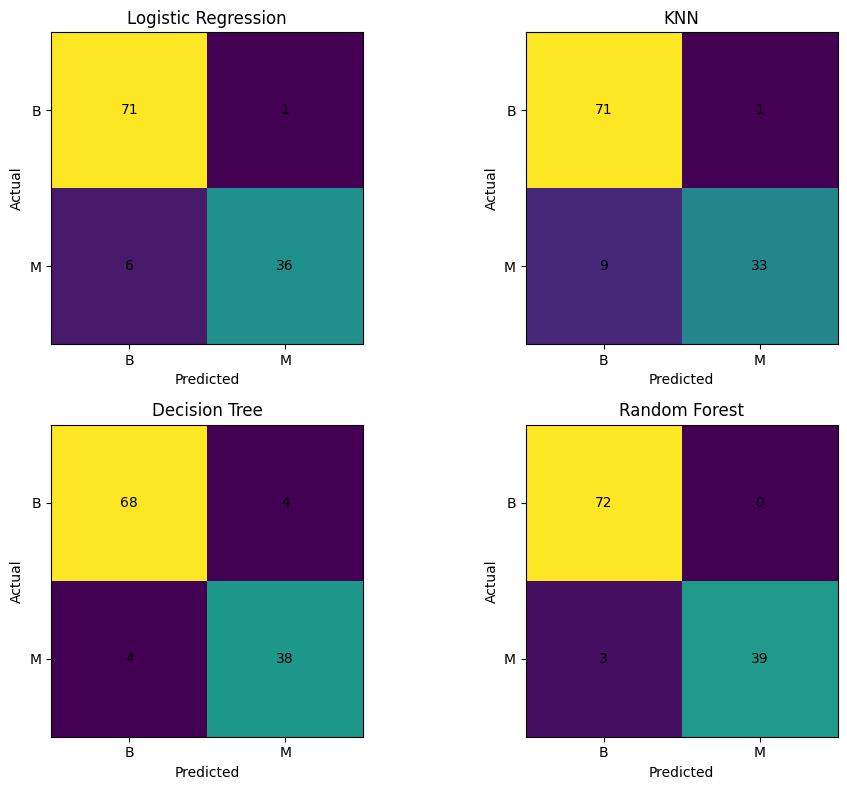

In [17]:
# Confusion matrices for baseline models

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for ax, (name, model) in zip(axes, baseline_models.items()):
    
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    ax.imshow(cm)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["B", "M"])
    ax.set_yticklabels(["B", "M"])
    
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [23]:
# standard versions of the four models

scaled_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),
    
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(random_state=42))
    ])
}

In [25]:
#standard training

scaled_model_results = {}

for name, model in scaled_models.items():
    model.fit(X_train, y_train)
    scaled_model_results[name] = model

In [26]:
#standard evaluation

scaled_results = []

for name, model in scaled_model_results.items():
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    scaled_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

scaled_results_df = pd.DataFrame(scaled_results)

display(
    scaled_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960
1,KNN,0.9561,0.9744,0.9048,0.9383,0.9823
2,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246
3,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929


In [27]:
# Compare baseline and standard

comparison_results = baseline_results_df.copy()

comparison_results = comparison_results.merge(
    scaled_results_df,
    on="Model",
    suffixes=("_Original", "_Standardized")
)

display(
    comparison_results.style.format({
        "Accuracy_Original": "{:.4f}",
        "Precision_Original": "{:.4f}",
        "Recall_Original": "{:.4f}",
        "F1_Original": "{:.4f}",
        "ROC-AUC_Original": "{:.4f}",
        "Accuracy_Standardized": "{:.4f}",
        "Precision_Standardized": "{:.4f}",
        "Recall_Standardized": "{:.4f}",
        "F1_Standardized": "{:.4f}",
        "ROC-AUC_Standardized": "{:.4f}"
    })
)

,Model,Accuracy_Original,Precision_Original,Recall_Original,F1_Original,ROC-AUC_Original,Accuracy_Standardized,Precision_Standardized,Recall_Standardized,F1_Standardized,ROC-AUC_Standardized
0,Logistic Regression,0.9386,0.9730,0.8571,0.9114,0.9924,0.9649,0.9750,0.9286,0.9512,0.9960
1,KNN,0.9123,0.9706,0.7857,0.8684,0.9547,0.9561,0.9744,0.9048,0.9383,0.9823
2,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246,0.9298,0.9048,0.9048,0.9048,0.9246
3,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929,0.9737,1.0000,0.9286,0.9630,0.9929


In [28]:
# Hyperparameter optimization

param_grids = {
    
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["liblinear", "lbfgs"]
    },
    
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },
    
    "Decision Tree": {
        "model__max_depth": [None, 3, 5, 7, 10],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2]
    }
}

print("Parameter grids created successfully.")

Parameter grids created successfully.


In [29]:
# Run hyperparameter optimization

optimized_models = {}
optimization_results = []

for name in scaled_models:
    
    print(f"Optimizing {name}...")
    
    grid_search = GridSearchCV(
        estimator=scaled_models[name],
        param_grid=param_grids[name],
        cv=5,
        scoring="f1",
        n_jobs=-1
    )
    
    grid_search.fit(X_train, y_train)
    
    optimized_models[name] = grid_search
    
    optimization_results.append({
        "Model": name,
        "Best CV F1": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

print("\nOptimization completed.")

Optimizing Logistic Regression...
Optimizing KNN...
Optimizing Decision Tree...
Optimizing Random Forest...

Optimization completed.


In [30]:
# Display best parameters

optimization_results_df = pd.DataFrame(optimization_results)

display(optimization_results_df)

,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.966213,"{'model__C': 0.1, 'model__solver': 'liblinear'}"
1,KNN,0.957283,"{'model__n_neighbors': 3, 'model__p': 1, 'mode..."
2,Decision Tree,0.922717,"{'model__max_depth': 7, 'model__min_samples_le..."
3,Random Forest,0.950094,"{'model__max_depth': None, 'model__min_samples..."


In [31]:
# Evaluate optimized models on the test set

optimized_results = []

for name, grid_search in optimized_models.items():
    
    best_model = grid_search.best_estimator_
    
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    
    optimized_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

optimized_results_df = pd.DataFrame(optimized_results)

display(
    optimized_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9825,1.0000,0.9524,0.9756,0.9977
1,KNN,0.9649,1.0000,0.9048,0.9500,0.9735
2,Decision Tree,0.9386,0.9487,0.8810,0.9136,0.9225
3,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929


In [32]:
# Prepare final comparison table

baseline_final = baseline_results_df.copy()
baseline_final["Experiment"] = "Original Data"

scaled_final = scaled_results_df.copy()
scaled_final["Experiment"] = "Standardized Data"

optimized_final = optimized_results_df.copy()
optimized_final["Experiment"] = "Optimized + Standardized"

final_results = pd.concat(
    [baseline_final, scaled_final, optimized_final],
    ignore_index=True
)

final_results = final_results[
    [
        "Experiment",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
]

display(
    final_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Original Data,Logistic Regression,0.9386,0.9730,0.8571,0.9114,0.9924
1,Original Data,KNN,0.9123,0.9706,0.7857,0.8684,0.9547
2,Original Data,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246
3,Original Data,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929
4,Standardized Data,Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960
5,Standardized Data,KNN,0.9561,0.9744,0.9048,0.9383,0.9823
6,Standardized Data,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246
7,Standardized Data,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929
8,Optimized + Standardized,Logistic Regression,0.9825,1.0000,0.9524,0.9756,0.9977
9,Optimized + Standardized,KNN,0.9649,1.0000,0.9048,0.9500,0.9735


In [33]:
# Compare standardized vs optimized models

improvement_results = scaled_results_df.merge(
    optimized_results_df,
    on="Model",
    suffixes=("_Standardized", "_Optimized")
)

improvement_results["Accuracy Improvement"] = (
    improvement_results["Accuracy_Optimized"]
    - improvement_results["Accuracy_Standardized"]
)

improvement_results["F1 Improvement"] = (
    improvement_results["F1_Optimized"]
    - improvement_results["F1_Standardized"]
)

improvement_results["ROC-AUC Improvement"] = (
    improvement_results["ROC-AUC_Optimized"]
    - improvement_results["ROC-AUC_Standardized"]
)

display(
    improvement_results[
        [
            "Model",
            "Accuracy_Standardized",
            "Accuracy_Optimized",
            "Accuracy Improvement",
            "F1_Standardized",
            "F1_Optimized",
            "F1 Improvement",
            "ROC-AUC_Standardized",
            "ROC-AUC_Optimized",
            "ROC-AUC Improvement"
        ]
    ].style.format({
        "Accuracy_Standardized": "{:.4f}",
        "Accuracy_Optimized": "{:.4f}",
        "Accuracy Improvement": "{:+.4f}",
        "F1_Standardized": "{:.4f}",
        "F1_Optimized": "{:.4f}",
        "F1 Improvement": "{:+.4f}",
        "ROC-AUC_Standardized": "{:.4f}",
        "ROC-AUC_Optimized": "{:.4f}",
        "ROC-AUC Improvement": "{:+.4f}"
    })
)

,Model,Accuracy_Standardized,Accuracy_Optimized,Accuracy Improvement,F1_Standardized,F1_Optimized,F1 Improvement,ROC-AUC_Standardized,ROC-AUC_Optimized,ROC-AUC Improvement
0,Logistic Regression,0.9649,0.9825,+0.0175,0.9512,0.9756,+0.0244,0.9960,0.9977,+0.0017
1,KNN,0.9561,0.9649,+0.0088,0.9383,0.9500,+0.0117,0.9823,0.9735,-0.0088
2,Decision Tree,0.9298,0.9386,+0.0088,0.9048,0.9136,+0.0088,0.9246,0.9225,-0.0021
3,Random Forest,0.9737,0.9737,+0.0000,0.9630,0.9630,+0.0000,0.9929,0.9929,+0.0000


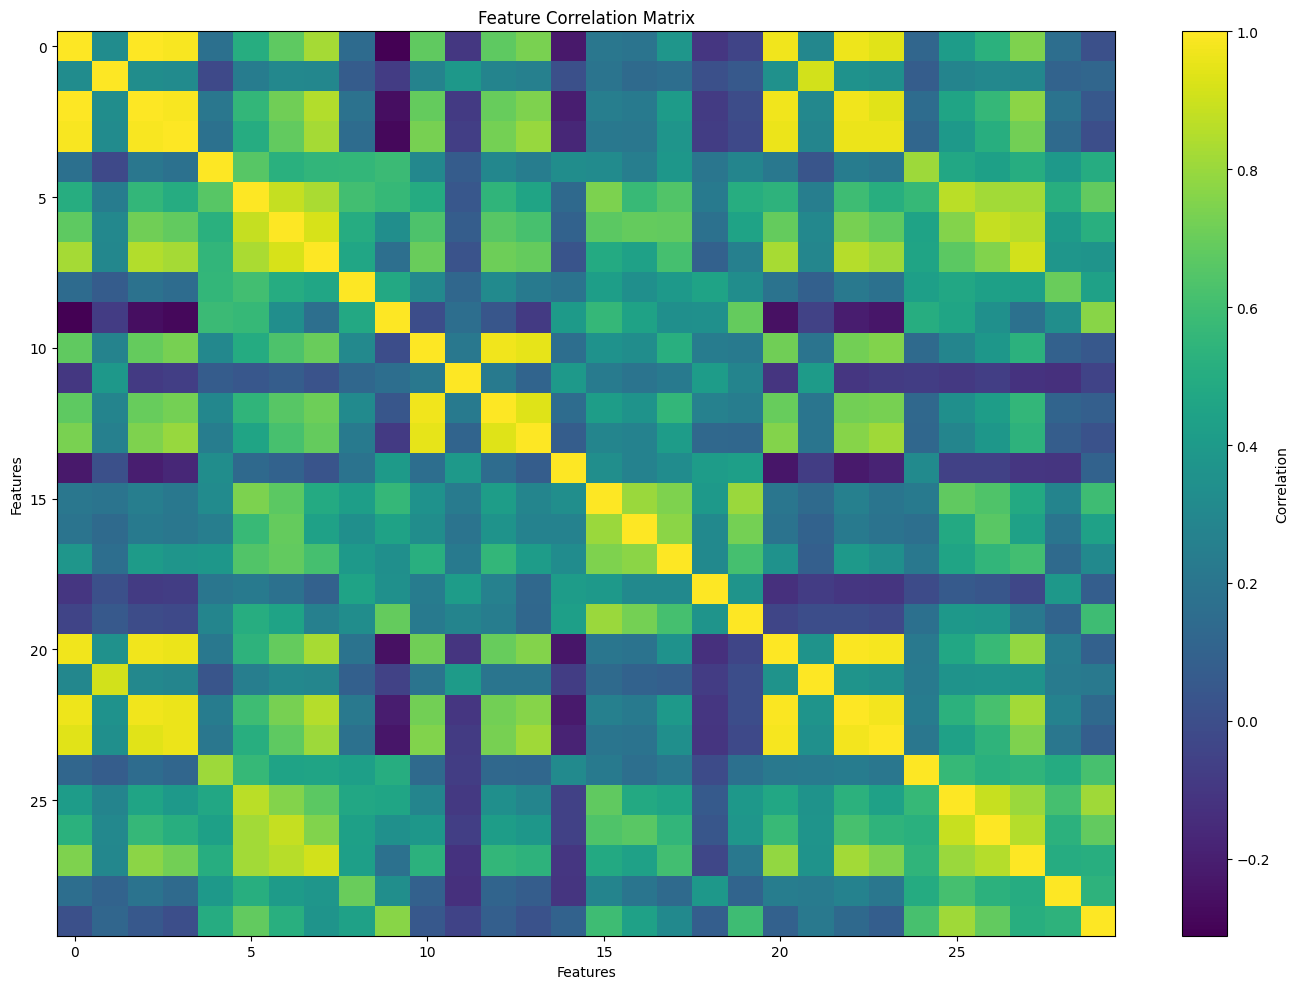

In [34]:
# Correlation heatmap

plt.figure(figsize=(14, 10))

correlation_matrix = X.corr()

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.title("Feature Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

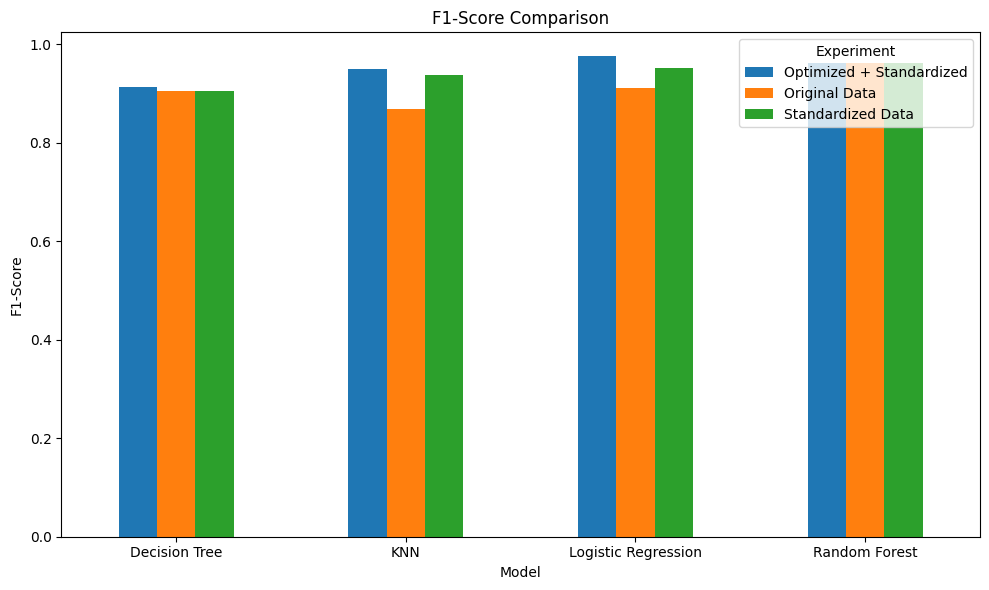

In [35]:
# Compare F1 scores across experiments

plot_data = final_results.pivot(
    index="Model",
    columns="Experiment",
    values="F1"
)

plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.legend(title="Experiment")
plt.tight_layout()
plt.show()

In [36]:
# Export all important results to Excel

output_file = "homework2_results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    
    # Dataset information
    dataset_info = pd.DataFrame({
        "Property": [
            "Dataset",
            "Observations",
            "Features",
            "Target",
            "Classes",
            "Missing Values",
            "Train/Test Split"
        ],
        "Value": [
            "Breast Cancer Wisconsin (Diagnostic)",
            X.shape[0],
            X.shape[1],
            "Diagnosis",
            "B = 0, M = 1",
            X.isnull().sum().sum(),
            "80% / 20%"
        ]
    })
    
    dataset_info.to_excel(
        writer,
        sheet_name="Dataset Info",
        index=False
    )
    
    baseline_results_df.to_excel(
        writer,
        sheet_name="Baseline Results",
        index=False
    )
    
    scaled_results_df.to_excel(
        writer,
        sheet_name="Standardized Results",
        index=False
    )
    
    optimization_results_df.to_excel(
        writer,
        sheet_name="Optimization",
        index=False
    )
    
    optimized_results_df.to_excel(
        writer,
        sheet_name="Optimized Results",
        index=False
    )
    
    final_results.to_excel(
        writer,
        sheet_name="Final Comparison",
        index=False
    )
    
    improvement_results.to_excel(
        writer,
        sheet_name="Improvements",
        index=False
    )

print(f"Excel file created: {output_file}")

Excel file created: homework2_results.xlsx
